# Dependencies

In [1]:
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)  # otherwise the 'params' dict column gets cut off
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))

# Data

In [2]:
def add_smoothed_features(df, selected_sensors, index_names, window=3):
    n_rows = len(df)
    df = df.sort_values(index_names)  

    rolling_cols = df.groupby('engine_id')[selected_sensors].rolling(window=window, min_periods=1).mean()
    rolling_cols = rolling_cols.reset_index(level=0, drop=True)
    rolling_cols.columns = [f"{c}_ma{window}" for c in selected_sensors]
    df = df.join(rolling_cols)
    features = rolling_cols.columns.tolist()
    

    assert df.shape[0] == n_rows 
    assert df[rolling_cols.columns].isna().sum().sum() == 0  
    return df, features


In [3]:
def add_slope_features(df, smoothed_cols, window=20):
    n_rows = len(df)

    slope_cols = df.groupby('engine_id')[smoothed_cols].diff(window) / window
    slope_cols.columns = [f"{c}_slope{window}" for c in smoothed_cols]
    slope_cols = slope_cols.fillna(0)  
    df = df.join(slope_cols)
    features = smoothed_cols + slope_cols.columns.tolist() + ['cycle']

    assert df.shape[0] == n_rows  
    assert df[slope_cols.columns].isna().sum().sum() == 0  
    return df, features


In [4]:
processed_dir = Path("../data")

index_names = ['engine_id', 'cycle']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = [f'sensor_{i}' for i in range(1, 22)]

excluded_columns = ['sensor_1', 'sensor_19', 'sensor_18', 'sensor_10', 'sensor_16', 'sensor_5', 'sensor_6']
selected_sensors = [sensor for sensor in sensor_names if sensor not in excluded_columns]
features = selected_sensors

### Train data

In [5]:
file_pat_fd001_train = processed_dir / f"labeled_train_FD001.csv"
train_df = pd.read_csv(file_pat_fd001_train)
train_df, train_smoothed_cols = add_smoothed_features(train_df, selected_sensors, index_names)
train_df, train_features = add_slope_features(train_df, train_smoothed_cols)

X_train = train_df[train_features]
y_train = train_df['rul_limited']
groups = train_df['engine_id']
X_train.describe()

,sensor_2_ma3,sensor_3_ma3,sensor_4_ma3,sensor_7_ma3,sensor_8_ma3,sensor_9_ma3,sensor_11_ma3,sensor_12_ma3,sensor_13_ma3,sensor_14_ma3,...,sensor_9_ma3_slope20,sensor_11_ma3_slope20,sensor_12_ma3_slope20,sensor_13_ma3_slope20,sensor_14_ma3_slope20,sensor_15_ma3_slope20,sensor_17_ma3_slope20,sensor_20_ma3_slope20,sensor_21_ma3_slope20,cycle
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,...,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,642.674485,1590.446267,1408.799110,553.380347,2388.095745,9065.032154,47.537131,521.424088,2388.095216,8143.604629,...,0.166617,0.003216,-8.528190e-03,0.000701,0.116623,0.000418,0.016325,-0.001964,-0.001195,108.807862
std,0.429922,5.134326,8.267217,0.810710,0.065705,21.339784,0.250644,0.686737,0.066600,18.494433,...,0.429754,0.005254,1.523024e-02,0.001493,0.363321,0.000899,0.041722,0.004458,0.002632,68.880990
min,641.450000,1573.020000,1387.306667,550.670000,2387.920000,9027.036667,46.930000,519.036667,2387.930000,8102.913333,...,-0.887000,-0.015667,-8.150000e-02,-0.004667,-0.832833,-0.003745,-0.166667,-0.022167,-0.012118,1.000000
25%,642.363333,1586.776667,1402.615000,552.896667,2388.046667,9053.556667,47.346667,521.015000,2388.046667,8133.391667,...,-0.040167,0.000000,-1.783333e-02,-0.000167,-0.054583,-0.000107,-0.016667,-0.004833,-0.002900,52.000000
50%,642.626667,1589.863333,1407.800000,553.453333,2388.093333,9060.410000,47.510000,521.483333,2388.093333,8140.460000,...,0.058833,0.002333,-6.500000e-03,0.000500,0.023833,0.000312,0.016667,-0.001500,-0.000872,104.000000
75%,642.940000,1593.480000,1413.790000,553.996667,2388.136667,9068.671667,47.685000,521.950000,2388.136667,8147.945000,...,0.246667,0.006333,5.684342e-15,0.001667,0.180167,0.000995,0.050000,0.000667,0.000323,156.000000
max,644.196667,1610.396667,1435.143333,555.376667,2388.446667,9230.333333,48.330000,523.003333,2388.440000,8287.280000,...,3.796167,0.028500,4.066667e-02,0.020000,3.162333,0.004238,0.200000,0.015667,0.008643,362.000000


### Test data

In [6]:
file_pat_fd001_test = processed_dir / f"labeled_test_FD001.csv"
test_df = pd.read_csv(file_pat_fd001_test)
test_df, test_smoothed_cols = add_smoothed_features(test_df, selected_sensors, index_names)
test_df, test_features = add_slope_features(test_df, test_smoothed_cols)

X_test = test_df[test_features]
y_test = test_df['rul_limited']
X_test.describe()

,sensor_2_ma3,sensor_3_ma3,sensor_4_ma3,sensor_7_ma3,sensor_8_ma3,sensor_9_ma3,sensor_11_ma3,sensor_12_ma3,sensor_13_ma3,sensor_14_ma3,...,sensor_9_ma3_slope20,sensor_11_ma3_slope20,sensor_12_ma3_slope20,sensor_13_ma3_slope20,sensor_14_ma3_slope20,sensor_15_ma3_slope20,sensor_17_ma3_slope20,sensor_20_ma3_slope20,sensor_21_ma3_slope20,cycle
count,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,...,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000,13096.000000
mean,642.471830,1588.061860,1404.670200,553.763729,2388.070482,9058.344737,47.414299,521.753239,2388.070548,8138.907992,...,0.053649,0.001625,-0.004493,0.000368,0.032184,0.000208,0.008105,-0.000982,-0.000574,76.836515
std,0.315940,3.730139,5.800476,0.592007,0.051385,10.776099,0.176467,0.498164,0.050893,9.754262,...,0.219348,0.004361,0.012569,0.001254,0.176065,0.000782,0.037055,0.004020,0.002381,53.057749
min,641.523333,1570.120000,1385.640000,551.130000,2387.920000,9031.296667,46.970000,519.543333,2387.923333,8111.240000,...,-0.756167,-0.015167,-0.066000,-0.004500,-0.599000,-0.002990,-0.150000,-0.018000,-0.010652,1.000000
25%,642.246667,1585.456667,1400.356667,553.370000,2388.030000,9051.216667,47.280000,521.433333,2388.030000,8132.316667,...,-0.055500,-0.000667,-0.012167,-0.000333,-0.053167,-0.000212,-0.016667,-0.003500,-0.002033,33.000000
50%,642.453333,1587.860000,1404.241667,553.813333,2388.066667,9057.286667,47.403333,521.786667,2388.066667,8138.410000,...,0.002833,0.000833,-0.002000,0.000167,0.000000,0.000047,0.000000,-0.000167,-0.000073,69.000000
75%,642.670000,1590.440000,1408.390000,554.200000,2388.106667,9063.637500,47.526667,522.126667,2388.106667,8144.077500,...,0.149042,0.004333,0.002000,0.001167,0.103667,0.000693,0.033333,0.001167,0.000695,113.000000
max,643.803333,1603.840000,1429.820000,555.336667,2388.280000,9150.230000,48.146667,523.003333,2388.273333,8217.453333,...,1.892667,0.025333,0.046167,0.006500,1.550167,0.003297,0.183333,0.019500,0.010252,303.000000


# Models

### Ridge

In [7]:
ridge_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), StandardScaler(), Ridge(alpha=2000))
start = time.perf_counter()
ridge_pipe.fit(X_train, y_train)
print(f"Ridge training time: {time.perf_counter() - start:.2f} s")

Ridge training time: 0.26 s


### Random Forest

In [8]:
rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=20, max_features='sqrt', oob_score=True, random_state=42))
start = time.perf_counter()
rf_pipe.fit(X_train, y_train)
print(f"Random Forest training time: {time.perf_counter() - start:.2f} s")
print(f"OOB R² = {rf_pipe.named_steps['randomforestregressor'].oob_score_:.4f}")

Random Forest training time: 9.77 s
OOB R² = 0.8975


### Gradient Boosting

In [9]:
hgb_pipe = make_pipeline(HistGradientBoostingRegressor(learning_rate=0.05, max_depth=3, max_iter=2000, early_stopping=True, random_state=42))
start = time.perf_counter()
hgb_pipe.fit(X_train, y_train)
print(f"Gradient Boosting training time: {time.perf_counter() - start:.2f} s")

Gradient Boosting training time: 2.66 s


# Results

In [10]:
y_pred_ridge = ridge_pipe.predict(X_test)
y_pred_rf = rf_pipe.predict(X_test)
y_pred_hgb = hgb_pipe.predict(X_test)

In [11]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    scores = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return scores.mean()


def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    nasa = nasa_score(y_true, y_pred)
    print(f"{name}: RMSE={rmse:.4f}, R²={r2:.4f}, NASA={nasa:.4f}")
    return {'Model': name, 'RMSE': rmse, 'R2': r2, 'NASA': nasa}


final_results = pd.DataFrame([
    evaluate('Ridge', y_test, y_pred_ridge),
    evaluate('Random Forest', y_test, y_pred_rf),
    evaluate('Gradient Boosting', y_test, y_pred_hgb),
])
final_results

Ridge: RMSE=15.9567, R²=0.6652, NASA=4.3656
Random Forest: RMSE=13.6409, R²=0.7554, NASA=3.2736
Gradient Boosting: RMSE=13.4140, R²=0.7634, NASA=3.0426


,Model,RMSE,R2,NASA
0,Ridge,15.956716,0.665248,4.365630
1,Random Forest,13.640917,0.755362,3.273588
2,Gradient Boosting,13.414012,0.763433,3.042628


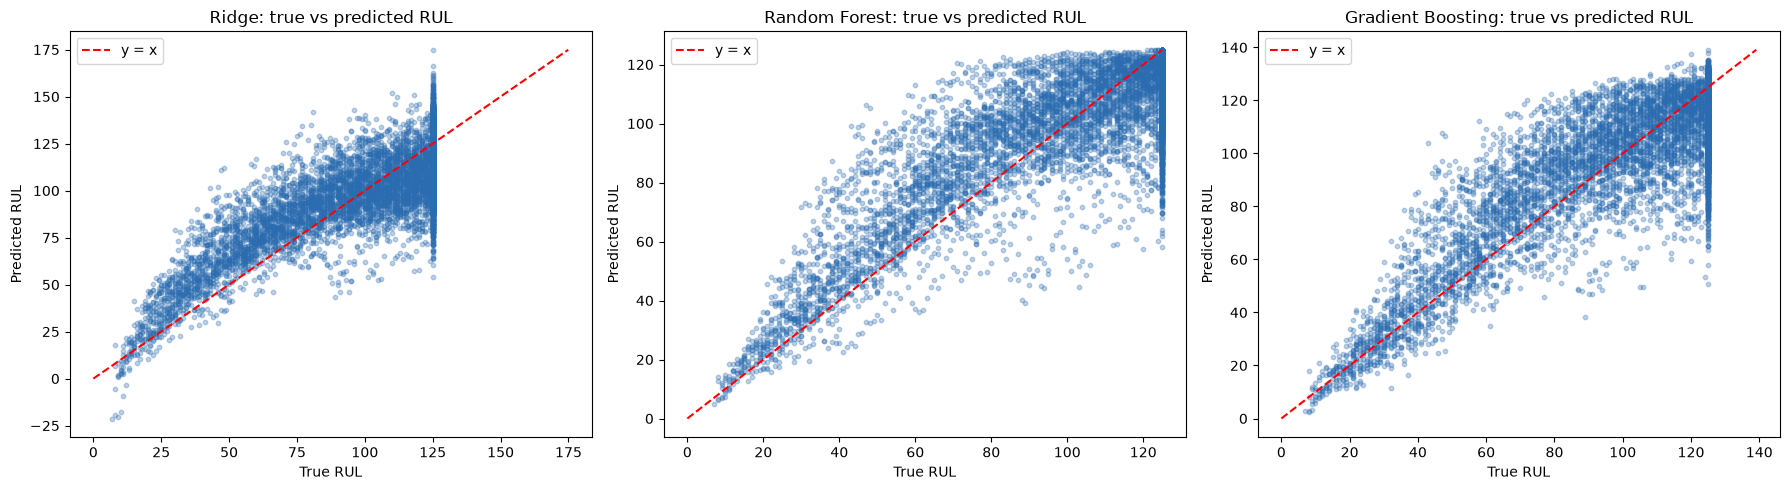

In [12]:
models_to_plot = [
    ('Ridge', y_pred_ridge),
    ('Random Forest', y_pred_rf),
    ('Gradient Boosting', y_pred_hgb),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model_name, y_pred) in zip(axes, models_to_plot):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10, color='#2b6cb0')
    lims = [0, max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", label="y = x")
    ax.set_xlabel("True RUL")
    ax.set_ylabel("Predicted RUL")
    ax.set_title(f"{model_name}: true vs predicted RUL")
    ax.legend()

plt.tight_layout()
plt.show()

Engine has enough history


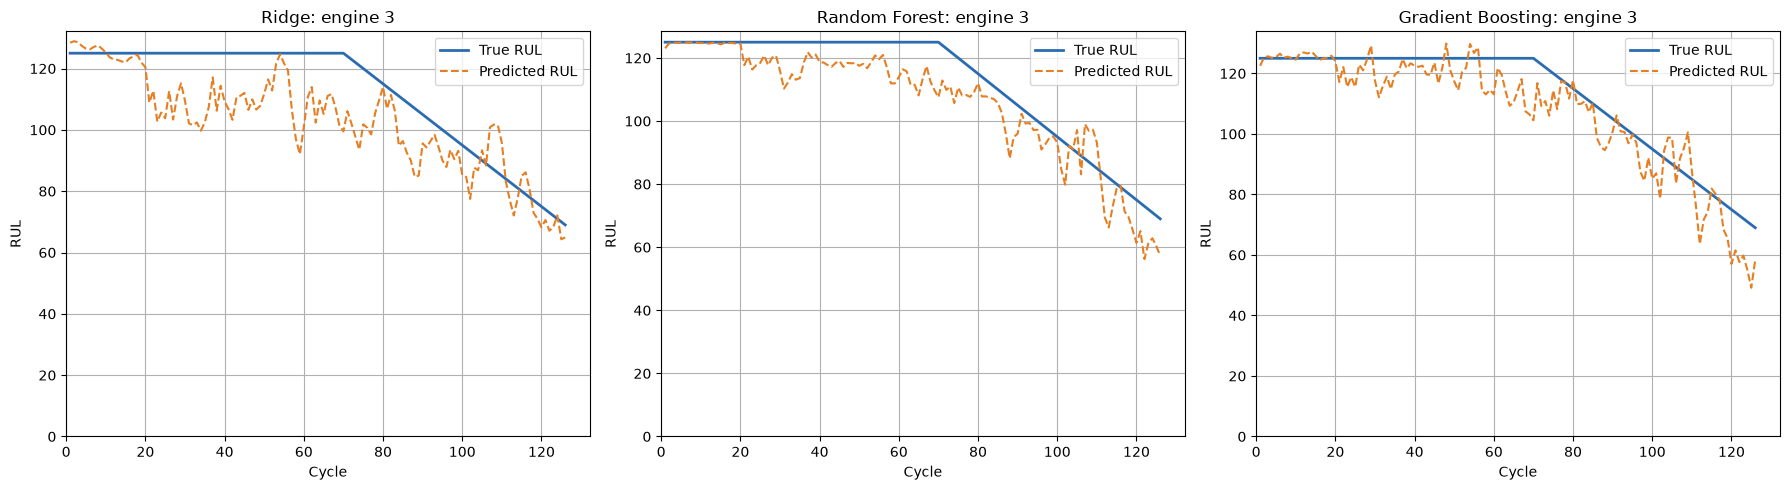

In [14]:
engine_id_example = 3
# engine_id_example = 1
engine_example = test_df[test_df['engine_id'] == engine_id_example].sort_values('cycle')
X_engine = engine_example[test_features]
y_engine_true = engine_example['rul_limited']  
cycle_engine = engine_example['cycle']

window_slope = 20  
cycles_observed = int(engine_example['cycle'].max())
has_enough_history = cycles_observed > window_slope
if not has_enough_history:
    print(f"Warning: engine {engine_id_example} has only {cycles_observed} cycles observed ")
else:
    print('Engine has enough history')

models_to_plot_engine = [
    ('Ridge', ridge_pipe),
    ('Random Forest', rf_pipe),
    ('Gradient Boosting', hgb_pipe),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (model_name, estimator) in zip(axes, models_to_plot_engine):
    y_engine_pred = estimator.predict(X_engine)
    ax.plot(cycle_engine, y_engine_true, label='True RUL', color='#2b6cb0', linewidth=2)
    ax.plot(cycle_engine, y_engine_pred, label='Predicted RUL', color='#e67e22', linewidth=1.5, linestyle='--')
    ax.set_xlim(left=0)   
    ax.set_ylim(bottom=0) 
    ax.set_xlabel('Cycle')
    ax.set_ylabel('RUL')
    ax.set_title(f'{model_name}: engine {engine_id_example}')
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.savefig('../outputs/Test_results.png')
plt.show()

In [15]:
# Keep only each engine's last cycle (official benchmark: one prediction per engine)
is_last = test_df['cycle'] == test_df.groupby('engine_id')['cycle'].transform('max')

y_test_last = y_test[is_last]
y_pred_ridge_last = y_pred_ridge[is_last.to_numpy()]
y_pred_rf_last = y_pred_rf[is_last.to_numpy()]
y_pred_hgb_last = y_pred_hgb[is_last.to_numpy()]

assert len(y_test_last) == 100  # one prediction per test engine

In [16]:
# Official benchmark metrics: one prediction per engine (last observed cycle only)
final_results_last = pd.DataFrame([
    evaluate('Ridge', y_test_last, y_pred_ridge_last),
    evaluate('Random Forest', y_test_last, y_pred_rf_last),
    evaluate('Gradient Boosting', y_test_last, y_pred_hgb_last),
])
final_results_last

Ridge: RMSE=15.1418, R²=0.8572, NASA=3.3366
Random Forest: RMSE=13.8494, R²=0.8806, NASA=2.8971
Gradient Boosting: RMSE=13.2777, R²=0.8902, NASA=2.7020


,Model,RMSE,R2,NASA
0,Ridge,15.141775,0.857228,3.336591
1,Random Forest,13.849402,0.880559,2.897092
2,Gradient Boosting,13.277673,0.890217,2.702035
